# 06 - Constant coefficients: the characteristic equation

**MATH 331 - Differential Equations.** Lecture plan: Sessions 11 and 12 (Unit 5: the characteristic equation with distinct real roots; complex and repeated roots; general solutions).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.2** (the opening example $y'' - 6y' + 8y = 0$; Theorems
  2.2.1-2.2.3; Examples 2.2.1-2.2.4; Euler's formula) and **Section 2.3** (Example 2.3.3).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), **Section
  3.3**: Example 7; Exercises 14 and 16. Their examples are written in the variable $t$; here
  they are rewritten in $x$, like the rest of the notebook.
* Related notebooks: 05 (two independent solutions are enough; the Wronskian), 07 (the same
  equation as a vibrating system). Videos R06 (roots of polynomials), R05 (complex numbers), R08
  (linear systems), R09 (Taylor series).

**What you will learn**
1. Why trying $y = e^{rx}$ turns a differential equation into an **algebraic** one.
2. The general solution in the three cases: two real roots, a repeated root, complex roots.
3. Where $x\,e^{rx}$ comes from, and how Euler's formula turns complex roots into oscillations.
4. How the position of the roots tells, before any computation, whether the solutions
   oscillate and whether they die out.

## 1. Theory in brief

**The equation.** $\;a\,y'' + b\,y' + c\,y = 0$ with constants $a \ne 0$, $b$, $c$.

**The idea.** Try $y = e^{rx}$: each derivative multiplies by $r$, so

$$ a\,y'' + b\,y' + c\,y = (a r^2 + b r + c)\,e^{rx} . $$

An exponential is never zero: $e^{rx}$ is a solution exactly when $r$ is a root of the
**characteristic equation** $\;a r^2 + b r + c = 0$.

**The three cases** (Lebl, Theorems 2.2.1 and 2.2.3), by the sign of $b^2 - 4ac$:

| $b^2 - 4ac$ | Roots | General solution |
|---|---|---|
| positive | $r_1 \ne r_2$, real | $C_1 e^{r_1x} + C_2 e^{r_2x}$ |
| zero | $r$, repeated | $(C_1 + C_2\,x)\,e^{rx}$ |
| negative | $\alpha \pm i\beta$ | $e^{\alpha x}\,(C_1\cos\beta x + C_2\sin\beta x)$ |

In each case the two functions are independent (notebook 05), so these are **all** the
solutions; the constants come from the initial conditions.

**Reading the roots.** An imaginary part means oscillation, with angular frequency $\beta$. The
real parts decide growth or decay: every solution tends to 0 exactly when both roots have a
negative real part, which (for $a > 0$) happens exactly when $b > 0$ and $c > 0$.

**Higher order.** The same for $a_n y^{(n)} + \dots + a_0 y = 0$: one exponential for each root of
the polynomial; a root repeated $m$ times gives $e^{rx}, x e^{rx}, \dots, x^{m-1}e^{rx}$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: characteristic_roots, constant_coefficient_solution, check, check_formula).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Two real roots

*Lebl, Section 2.2, the opening example.* $\;y'' - 6y' + 8y = 0$, $\;y(0) = -2$, $\;y'(0) = 6$.

By hand:

1. Characteristic equation: $r^2 - 6r + 8 = (r - 2)(r - 4) = 0$, so $r = 2$ and $r = 4$ (video
   R06).
2. General solution: $y = C_1 e^{2x} + C_2 e^{4x}$.
3. Initial conditions, a 2 x 2 system (video R08): $\;C_1 + C_2 = -2$, $\;2C_1 + 4C_2 = 6$. So
   $C_2 = 5$, $C_1 = -7$:

$$ y = -7\,e^{2x} + 5\,e^{4x} . $$

Why try an exponential at all? For $y' = ky$ the answer was $e^{kx}$ (notebook 01): exponentials
are the functions whose derivatives are multiples of themselves.

In [2]:
x, r = sp.symbols("x r")
a, b, c = sp.symbols("a b c")
C1, C2 = sp.symbols("C1 C2")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


def left_side(y, coefficients):
    # a y'' + b y' + c y for the coefficients (a, b, c)
    first, second, third = coefficients
    return first * sp.diff(y, x, 2) + second * sp.diff(y, x) + third * y


def with_initial_values(general, position, velocity):
    # the constants C1, C2 of a general solution, from y(0) and y'(0)
    constants = sp.solve([general.subs(x, 0) - position, sp.diff(general, x).subs(x, 0) - velocity], [C1, C2])
    return sp.simplify(general.subs(constants))


print("the key identity:", sp.simplify(left_side(sp.exp(r * x), (a, b, c)) / sp.exp(r * x)), "times exp(r x)")

OPENING = (1, -6, 8)                            # Lebl, Section 2.2
print("roots:", sp.solve(r ** 2 - 6 * r + 8, r))
opening = with_initial_values(C1 * sp.exp(2 * x) + C2 * sp.exp(4 * x), -2, 6)
print("solution: y =", sp.expand(opening))

assert residual(left_side(opening, OPENING)) == 0
assert residual(opening, -7 * sp.exp(2 * x) + 5 * sp.exp(4 * x)) == 0                # the solution of the book

the key identity: a*r**2 + b*r + c times exp(r x)
roots: [2, 4]
solution: y = 5*exp(4*x) - 7*exp(2*x)


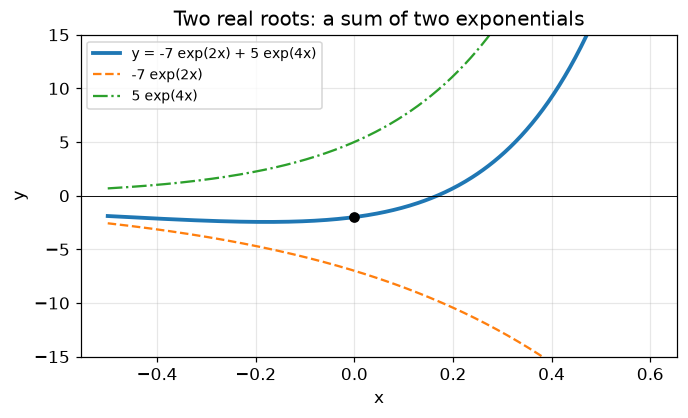

In [3]:
FIGURE_SIZE = (7.0, 3.8)
WIDE_FIGURE = (9.5, 3.8)
N_POINTS = 400
OPENING_RANGE = (-0.5, 0.6)
OPENING_LIMITS = (-15.0, 15.0)

points = np.linspace(*OPENING_RANGE, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, ol.constant_coefficient_solution(points, *OPENING, -2, 6), "-", linewidth=2.5,
        label="y = -7 exp(2x) + 5 exp(4x)")
ax.plot(points, -7 * np.exp(2 * points), "--", label="-7 exp(2x)")
ax.plot(points, 5 * np.exp(4 * points), "-.", label="5 exp(4x)")
ax.plot(0.0, -2.0, "o", color="black")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_ylim(*OPENING_LIMITS)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Two real roots: a sum of two exponentials")
ax.legend(loc="upper left")
plt.show()

*The plot shows* the solution (solid) through the black dot $(0, -2)$: almost flat on the left (its
lowest point, $-2.45$, is near $x = -0.18$), then rising and crossing the axis once, near $x = 0.17$. The two pieces it is made of are also drawn: $-7e^{2x}$
(dashed), always negative, and $5e^{4x}$ (dash-dot), always positive. On the right the faster
exponential, $e^{4x}$, wins.

With two real roots a solution that is not identically zero crosses zero **at most once**: $C_1e^{r_1x} + C_2e^{r_2x} = 0$
means $e^{(r_1 - r_2)x} = -C_2/C_1$, which has at most one solution. No oscillation.

*Lebl, Example 2.2.1.* $y'' - k^2y = 0$ has $r = \pm k$: $\;y = C_1e^{kx} + C_2e^{-kx}$.

## 3. A repeated root

*Lebl, Example 2.2.2.* $\;y'' - 8y' + 16y = 0$. The characteristic equation is $(r - 4)^2 = 0$: only
one root, $r = 4$, and only one exponential, $e^{4x}$. Two independent solutions are needed
(notebook 05). The second one is $x\,e^{4x}$:

$$ y = (C_1 + C_2\,x)\,e^{4x} . $$

**Where does the factor $x$ come from?** Lebl's explanation: a repeated root is the limit of two
roots that come together. When $r_1 \ne r_2$, the combination

$$ \frac{e^{r_2x} - e^{r_1x}}{r_2 - r_1} $$

is a solution (superposition). As $r_2 \to r_1 = r$ this is a difference quotient in the variable
$r$, and its limit is the derivative of $e^{rx}$ with respect to $r$: $\;x\,e^{rx}$.

(Another route to the same function is reduction of order: notebook 05, Section 6.)

*Adkins and Davidson, Section 3.3, Example 7* (in $x$): $\;y'' + 2y' + y = 0$, $y(0) = 2$,
$y'(0) = -3$. One root, $r = -1$; $y = (C_1 + C_2x)e^{-x}$ with $C_1 = 2$ and $-C_1 + C_2 = -3$:
$\;y = (2 - x)\,e^{-x}$.

In [4]:
h = sp.symbols("h")
print("limit of the difference quotient:", sp.limit((sp.exp((r + h) * x) - sp.exp(r * x)) / h, h, 0))

LEBL_REPEATED = (1, -8, 16)
for candidate in (sp.exp(4 * x), x * sp.exp(4 * x)):
    assert residual(left_side(candidate, LEBL_REPEATED)) == 0

ADKINS_REPEATED = (1, 2, 1)
adkins = with_initial_values((C1 + C2 * x) * sp.exp(-x), 2, -3)
print("Adkins and Davidson, Example 7: y =", adkins)
assert residual(adkins, (2 - x) * sp.exp(-x)) == 0 and residual(left_side(adkins, ADKINS_REPEATED)) == 0

limit of the difference quotient: x*exp(r*x)
Adkins and Davidson, Example 7: y = (2 - x)*exp(-x)


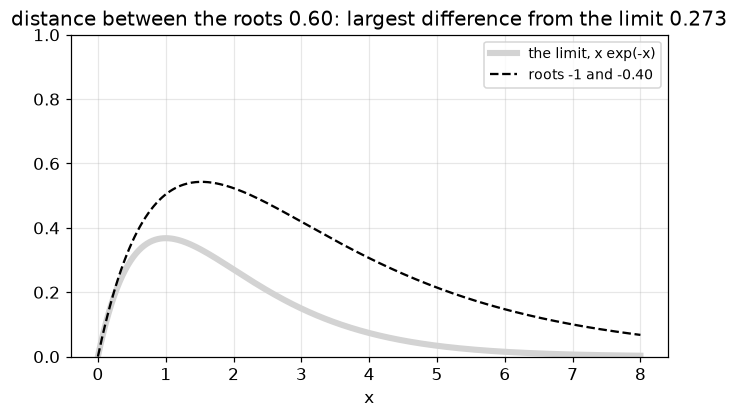

In [5]:
FIXED_ROOT = -1.0
MERGE_RANGE = (0.0, 8.0)
DEFAULT_GAP = 0.6


def plot_merging_roots(gap=DEFAULT_GAP):
    # the solution (exp(r2 x) - exp(r1 x)) / (r2 - r1) for r1 = -1 and r2 = -1 + gap, and its limit x exp(-x)
    points = np.linspace(*MERGE_RANGE, N_POINTS)
    other_root = FIXED_ROOT + gap
    quotient = (np.exp(other_root * points) - np.exp(FIXED_ROOT * points)) / gap
    limit = points * np.exp(FIXED_ROOT * points)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(points, limit, "-", linewidth=4, color="lightgray", label="the limit, x exp(-x)")
    ax.plot(points, quotient, "--", color="black", linewidth=1.5, label=f"roots -1 and {other_root:.2f}")
    ax.set_ylim(0.0, 1.0)
    ax.set_xlabel("x")
    ax.set_title(f"distance between the roots {gap:.2f}: largest difference from the limit {np.max(np.abs(quotient - limit)):.3f}")
    ax.legend(loc="upper right")
    plt.show()


plot_merging_roots()

*The plot shows* the function $x\,e^{-x}$ (thick grey): it starts at 0, rises to its maximum
$1/e$ at $x = 1$ and decays. The dashed black curve is the combination of two exponentials with
roots $-1$ and $-0.4$: the same kind of hump, but higher and later.

**Slider.** Before moving it: what happens to the dashed curve as the two roots come together?

In [6]:
GAP_RANGE = (0.01, 0.9, 0.01)               # minimum, maximum, step

interact(plot_merging_roots, gap=FloatSlider(value=DEFAULT_GAP, min=GAP_RANGE[0], max=GAP_RANGE[1], step=GAP_RANGE[2],
                                             description="distance", continuous_update=False));

interactive(children=(FloatSlider(value=0.6, continuous_update=False, description='distance', max=0.9, min=0.0...

(It settles onto the grey curve: the factor $x$ is what is left of two exponentials when their
rates become equal.)

## 4. Complex roots

When $b^2 - 4ac < 0$ the roots are a conjugate pair $r = \alpha \pm i\beta$ (video R05), with
$\alpha = -\dfrac{b}{2a}$ and $\beta = \dfrac{\sqrt{4ac - b^2}}{2a}$. The exponentials
$e^{(\alpha \pm i\beta)x}$ are still solutions, but complex. **Euler's formula** (Lebl, Theorem
2.2.2; video R09 derives it from the Taylor series)

$$ e^{i\theta} = \cos\theta + i\sin\theta $$

gives $\;e^{(\alpha \pm i\beta)x} = e^{\alpha x}\,(\cos\beta x \pm i\sin\beta x)$. By superposition,
half the sum and $\tfrac{1}{2i}$ times the difference of these two solutions are solutions too,
and they are real:

$$ \boxed{\;y = e^{\alpha x}\,\big(C_1\cos\beta x + C_2\sin\beta x\big)\;} \qquad \text{(Lebl, Theorem 2.2.3).} $$

**Reading it.** $\beta$ is the angular frequency of the oscillation (period $2\pi/\beta$);
$e^{\alpha x}$ is the *envelope*: it grows if $\alpha > 0$ and decays if $\alpha < 0$.

**One cosine instead of two functions.** $\;C_1\cos\beta x + C_2\sin\beta x = A\cos(\beta x - \gamma)$
with the amplitude $A = \sqrt{C_1^2 + C_2^2}$ and the phase $\gamma$, the angle of the point $(C_1, C_2)$:
$\cos\gamma = C_1/A$, $\sin\gamma = C_2/A$ (so $\tan\gamma = C_2/C_1$, with $\gamma$ in the quadrant of that point).
Notebook 07 uses this form.

*Lebl, Example 2.2.3.* $y'' + k^2y = 0$: $r = \pm ik$, $\;y = C_1\cos kx + C_2\sin kx$.

*Lebl, Example 2.2.4.* $y'' - 6y' + 13y = 0$, $y(0) = 0$, $y'(0) = 10$. By hand:
$r = \dfrac{6 \pm \sqrt{36 - 52}}{2} = 3 \pm 2i$, so $y = e^{3x}(C_1\cos 2x + C_2\sin 2x)$;
$y(0) = C_1 = 0$ and $y'(0) = 3C_1 + 2C_2 = 10$ give $C_2 = 5$: $\;y = 5\,e^{3x}\sin 2x$.

exp(i theta) = I*sin(theta) + cos(theta)
roots: [3 - 2*I, 3 + 2*I]    odelib: ((3+2j), (3-2j))
solution: y = 5*exp(3*x)*sin(2*x)


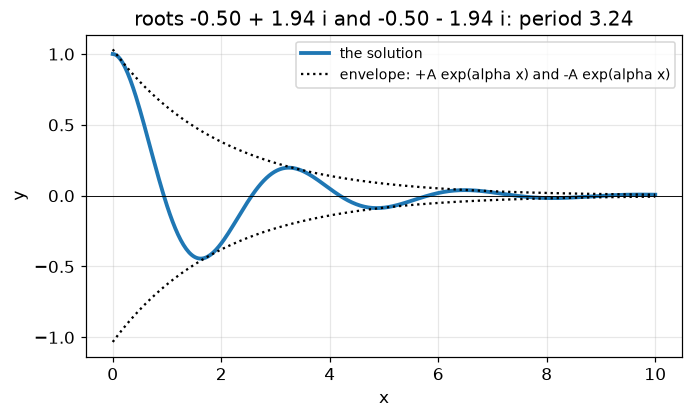

alpha = -0.500, beta = 1.936, period 2 pi / beta = 3.245, amplitude A = 1.033


In [7]:
theta = sp.symbols("theta", real=True)
print("exp(i theta) =", sp.expand_complex(sp.exp(sp.I * theta)))

LEBL_COMPLEX = (1, -6, 13)
print("roots:", sp.solve(r ** 2 - 6 * r + 13, r), "   odelib:", ol.characteristic_roots(*LEBL_COMPLEX))
lebl_complex = with_initial_values(sp.exp(3 * x) * (C1 * sp.cos(2 * x) + C2 * sp.sin(2 * x)), 0, 10)
print("solution: y =", lebl_complex)
assert residual(lebl_complex, 5 * sp.exp(3 * x) * sp.sin(2 * x)) == 0                 # the solution of the book
assert residual(left_side(lebl_complex, LEBL_COMPLEX)) == 0

# A picture of the three ingredients, on an equation whose oscillation dies out slowly enough to be drawn:
# y'' + y' + 4y = 0, y(0) = 1, y'(0) = 0  (Lebl's example grows about 110 times every half period)
GENTLE = (1.0, 1.0, 4.0)
COMPLEX_RANGE = (0.0, 10.0)
alpha, beta = ol.characteristic_roots(*GENTLE)[0].real, abs(ol.characteristic_roots(*GENTLE)[0].imag)
amplitude = np.hypot(1.0, -alpha / beta)       # y = exp(alpha x) (cos(beta x) - (alpha / beta) sin(beta x))
points = np.linspace(*COMPLEX_RANGE, N_POINTS)
gentle = ol.constant_coefficient_solution(points, *GENTLE, 1.0, 0.0)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, gentle, "-", linewidth=2.5, label="the solution")
ax.plot(points, amplitude * np.exp(alpha * points), ":", color="black", label="envelope: +A exp(alpha x) and -A exp(alpha x)")
ax.plot(points, -amplitude * np.exp(alpha * points), ":", color="black")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"roots {alpha:.2f} + {beta:.2f} i and {alpha:.2f} - {beta:.2f} i: period {2 * np.pi / beta:.2f}")
ax.legend(loc="upper right")
plt.show()

print(f"alpha = {alpha:.3f}, beta = {beta:.3f}, period 2 pi / beta = {2 * np.pi / beta:.3f}, amplitude A = {amplitude:.3f}")
assert np.all(np.abs(gentle) <= amplitude * np.exp(alpha * points) + 1e-12)        # the solution stays inside

*The plot shows* the solution of $y'' + y' + 4y = 0$ with $y(0) = 1$, $y'(0) = 0$ (solid): an
oscillation with period about 3.2 that shrinks at every swing. The two dotted curves are the
envelope $\pm A\,e^{\alpha x}$ with $\alpha = -\tfrac12$: the solution stays between them and
touches each of them once per period. The roots are $-0.5 \pm 1.94\,i$: the real part gives the envelope,
the imaginary part the frequency.

(Lebl's example above has $\alpha = +3$: its oscillation *grows*, by a factor of about 110 at
every half period, far too fast to be drawn on one picture.)

## 5. The roots decide the shape

For $y'' + b\,y' + c\,y = 0$ (take $a = 1$), mark the two roots in the complex plane:

* roots **off the real axis**: the solutions oscillate, the faster the further the roots are
  from the axis;
* roots in the **left half** of the plane (negative real part): the solutions die out; in the
  **right half**: they grow;
* both roots are in the left half exactly when $b > 0$ and $c > 0$. (Because $r_1 + r_2 = -b$
  and $r_1r_2 = c$: two real roots with a positive product and a negative sum are both negative;
  two complex roots have real part $-b/2$.)

The picture shows the roots and the solution with $y(0) = 1$, $y'(0) = 0$.

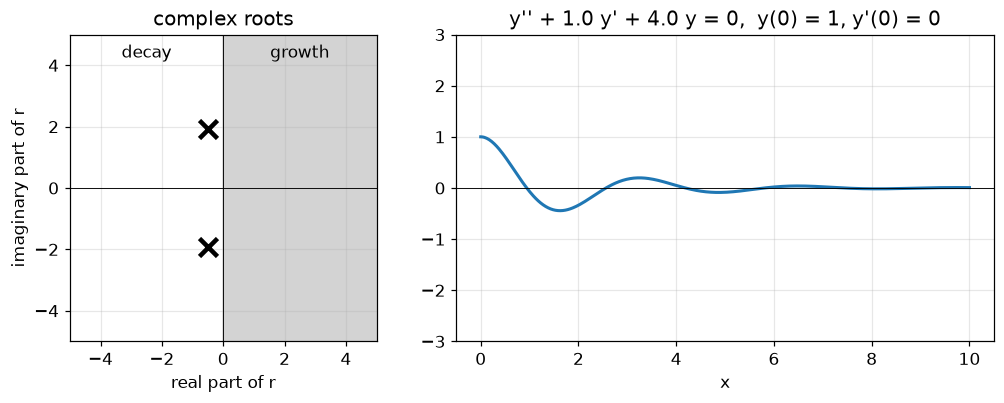

In [8]:
PLANE = (-5.0, 5.0)
SOLUTION_RANGE = (0.0, 10.0)
SOLUTION_LIMITS = (-3.0, 3.0)
DEFAULT_B, DEFAULT_C = 1.0, 4.0
EXACT = 1e-12                               # below this, the discriminant counts as zero


def plot_roots(b=DEFAULT_B, c=DEFAULT_C):
    # the roots of r^2 + b r + c in the complex plane, and the solution with y(0) = 1, y'(0) = 0
    first, second = ol.characteristic_roots(1.0, b, c)
    discriminant = b * b - 4 * c
    if abs(discriminant) <= EXACT:
        case = "a repeated root"
    else:
        case = "two real roots" if discriminant > 0 else "complex roots"
    points = np.linspace(*SOLUTION_RANGE, N_POINTS)
    values = ol.constant_coefficient_solution(points, 1.0, b, c, 1.0, 0.0)
    fig, (plane, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE, gridspec_kw={"width_ratios": (2, 3)})
    plane.axvspan(0.0, PLANE[1], color="lightgray")
    plane.plot([first.real, second.real], [first.imag, second.imag], "x", markersize=12, markeredgewidth=3, color="black")
    plane.axhline(0.0, color="black", linewidth=0.6)
    plane.axvline(0.0, color="black", linewidth=0.6)
    plane.text(PLANE[0] / 2, 0.85 * PLANE[1], "decay", ha="center")
    plane.text(PLANE[1] / 2, 0.85 * PLANE[1], "growth", ha="center")
    plane.set_xlim(*PLANE)
    plane.set_ylim(*PLANE)
    plane.set_aspect("equal")
    plane.set_xlabel("real part of r")
    plane.set_ylabel("imaginary part of r")
    plane.set_title(case)
    right.plot(points, np.clip(values, *SOLUTION_LIMITS), "-", linewidth=2)
    right.axhline(0.0, color="black", linewidth=0.6)
    right.set_ylim(*SOLUTION_LIMITS)
    right.set_xlabel("x")
    right.set_title(f"y'' + {b:.1f} y' + {c:.1f} y = 0,  y(0) = 1, y'(0) = 0")
    plt.tight_layout()
    plt.show()


plot_roots()

*The plot shows* two panels. Left: the complex plane, its right half shaded grey and labelled
"growth", its left half labelled "decay"; two crosses mark the roots of $r^2 + r + 4$, at
$-0.5 \pm 1.94\,i$: off the real axis and in the left half. Right: the solution, an oscillation
that starts at 1 and dies out.

**Sliders.** Predict the shape of the solution *before* moving them, for:

1. $b = 0$, $c = 4$;
2. $b = 4$, $c = 4$;
3. $b = 5$, $c = 4$;
4. $c = -1$ (any $b$);
5. $b = -1$, $c = 4$.

In [9]:
B_RANGE = (-2.0, 6.0, 0.1)                  # minimum, maximum, step
C_RANGE = (-3.0, 9.0, 0.1)

interact(plot_roots,
         b=FloatSlider(value=DEFAULT_B, min=B_RANGE[0], max=B_RANGE[1], step=B_RANGE[2], description="b",
                       continuous_update=False),
         c=FloatSlider(value=DEFAULT_C, min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2], description="c",
                       continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='b', max=6.0, min=-2.0), Flo...

(1: roots $\pm 2i$ on the imaginary axis: an oscillation that neither grows nor dies. 2: a
repeated root $-2$: decay without oscillation. 3: roots $-1$ and $-4$: the same, slower at the
end. 4: one positive real root: growth. 5: complex roots in the right half: an oscillation that
grows.)

## 6. Higher order

For an equation of order $n$ with constant coefficients the idea is the same: $e^{rx}$ is a
solution exactly when $r$ is a root of the characteristic polynomial, now of degree $n$ (video
R06 for how to find the roots).

*Lebl, Example 2.3.3.* $\;y''' - 3y'' - y' + 3y = 0$: $\;r^3 - 3r^2 - r + 3 = (r - 3)(r - 1)(r + 1)$, so
$y = C_1e^{3x} + C_2e^{x} + C_3e^{-x}$. Three constants, for three initial conditions: the linear
system of notebook 08 (Section 4) is exactly the one of this example.

A root repeated three times, $(r + 1)^3 = 0$: $\;y = (C_1 + C_2x + C_3x^2)\,e^{-x}$. More on roots
of any multiplicity in notebook 16.

In [10]:
cubic = r ** 3 - 3 * r ** 2 - r + 3
print("factors:", sp.factor(cubic), "   roots:", sp.solve(cubic, r))
for root in sp.solve(cubic, r):
    candidate = sp.exp(root * x)
    assert residual(sp.diff(candidate, x, 3) - 3 * sp.diff(candidate, x, 2) - sp.diff(candidate, x) + 3 * candidate) == 0

for power in range(3):                         # the triple root -1
    candidate = x ** power * sp.exp(-x)
    assert residual(sp.diff(candidate, x, 3) + 3 * sp.diff(candidate, x, 2) + 3 * sp.diff(candidate, x) + candidate) == 0
print("exp(-x), x exp(-x) and x^2 exp(-x) all solve y''' + 3y'' + 3y' + y = 0")

factors: (r - 3)*(r - 1)*(r + 1)    roots: [-1, 1, 3]
exp(-x), x exp(-x) and x^2 exp(-x) all solve y''' + 3y'' + 3y' + y = 0


## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

For each equation say, from $b$ and $c$ only, whether the solutions **oscillate** and whether
they all **tend to zero**. Type two lists of `True` and `False`.

1. $y'' + 4y = 0$
2. $y'' + 2y' + 5y = 0$
3. $y'' + 5y' + 4y = 0$
4. $y'' - y = 0$
5. $y'' + 4y' + 4y = 0$
6. $y'' - 2y' + 5y = 0$

In [11]:
my_oscillate = None             # six values, for example [True, True, True, True, True, True]
my_tend_to_zero = None          # six values
# ---- your answers go above this line; the lines below check them (nothing to change) ----

EQUATIONS = ((0, 4), (2, 5), (5, 4), (0, -1), (4, 4), (-2, 5))          # (b, c)
oscillate = [bool(abs(ol.characteristic_roots(1.0, b_value, c_value)[0].imag) > EXACT) for b_value, c_value in EQUATIONS]
decay = [bool(max(root.real for root in ol.characteristic_roots(1.0, b_value, c_value)) < 0) for b_value, c_value in EQUATIONS]

ol.check("Exercise 1, oscillate", my_oscillate, oscillate)
ol.check("Exercise 1, tend to zero", my_tend_to_zero, decay);

Exercise 1, oscillate: no answer yet (replace None with your value)
Exercise 1, tend to zero: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

Solve each initial value problem by hand and type the solution as a formula in `x` (use `sp.exp`,
`sp.cos`, `sp.sin`).

**(a)** *Adkins and Davidson, Section 3.3, Exercise 14.* $\;y'' - 3y' - 10y = 0$, $y(0) = 5$,
$y'(0) = 4$.

**(b)** *Adkins and Davidson, Section 3.3, Exercise 16.* $\;y'' + 4y' + 13y = 0$, $y(0) = 1$,
$y'(0) = -5$.

**(c)** $\;y'' + 8y' + 16y = 0$, $y(0) = 1$, $y'(0) = 0$.

In [12]:
my_a = None
my_b = None
my_c = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

X_INTERVAL = (0.0, 1.0)
PROBLEMS = (("Exercise 2a", (1, -3, -10), 5, 4), ("Exercise 2b", (1, 4, 13), 1, -5), ("Exercise 2c", (1, 8, 16), 1, 0))
unknown = sp.Function("y")

for (label, coefficients, position, velocity), answer in zip(PROBLEMS, (my_a, my_b, my_c)):
    expected = sp.dsolve(left_side(unknown(x), coefficients), unknown(x),
                         ics={unknown(0): position, unknown(x).diff(x).subs(x, 0): velocity}).rhs
    ol.check_formula(label, answer, expected, x, X_INTERVAL)

Exercise 2a: no answer yet (replace None with your formula)


Exercise 2b: no answer yet (replace None with your formula)


Exercise 2c: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Complete the function `roots`, which returns the two roots of $a r^2 + b r + c = 0$, also when
they are complex. `np.sqrt(complex(d))` is the square root of a number `d` that may be negative.
The next cell tries it on the equations of this notebook.

In [13]:
def roots(a, b, c):
    return None                 # replace None with the formula

In [14]:
if roots(1.0, 0.0, 1.0) is None:
    print("Exercise 3: complete roots first")
else:
    for coefficients in (OPENING, LEBL_REPEATED, ADKINS_REPEATED, LEBL_COMPLEX, (2, 3, 5)):
        mine = sorted(np.atleast_1d(np.array(roots(*coefficients), dtype=complex)), key=lambda z: (z.real, z.imag))
        theirs = sorted(ol.characteristic_roots(*coefficients), key=lambda z: (z.real, z.imag))
        assert len(mine) == 2 and np.allclose(mine, theirs), f"wrong roots for a, b, c = {coefficients}"
    print("Exercise 3: correct; for Lebl's Example 2.2.4 the roots are", np.round(roots(*LEBL_COMPLEX), 3))

Exercise 3: complete roots first


### Exercise 4 - Explore

* For which values of $c$ do the solutions of $y'' + 2y' + c\,y = 0$ oscillate? Find the answer by
  hand, then check with the sliders of Section 5.
* For which real $k$ do all the solutions of $y'' + k\,y' + 4y = 0$ tend to zero? For which $k$ do
  they oscillate?
* Find the general solution of $y''' - y = 0$. (One real root and a complex pair: factor
  $r^3 - 1$, or ask `sp.solve`.)
* Write the solution of Exercise 2(b) as one cosine, $A\,e^{-2x}\cos(3x - \gamma)$: what are $A$
  and $\gamma$?

In [15]:
# your code here

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. Oscillate: `[True, True, False, False, False, True]`. Tend to zero:
   `[False, True, True, False, True, False]`. (Roots: $\pm 2i$; $-1 \pm 2i$; $-1, -4$; $\pm 1$;
   $-2$ twice; $1 \pm 2i$.)
2. (a) Roots 5 and $-2$: $y = 2e^{5x} + 3e^{-2x}$. (b) Roots $-2 \pm 3i$:
   $y = e^{-2x}(\cos 3x - \sin 3x)$. (c) Root $-4$ twice: $y = (1 + 4x)\,e^{-4x}$.
3. `d = np.sqrt(complex(b * b - 4 * a * c))` and then
   `return (-b + d) / (2 * a), (-b - d) / (2 * a)`
4. They oscillate for $c > 1$. They all tend to zero for $k > 0$, and oscillate for
   $-4 < k < 4$. $\;y = C_1e^{x} + e^{-x/2}\big(C_2\cos\tfrac{\sqrt3}{2}x + C_3\sin\tfrac{\sqrt3}{2}x\big)$.
   $A = \sqrt2$ and $\gamma = -\tfrac{\pi}{4}$.

</details>

**Where to go next:** notebook 14 (the same equations with a right-hand side) and notebook 07
(the same equation as a mass on a spring with a damper). The
optional notebook 05E shows why the formulas of this notebook give **all** the solutions, and how
they agree with Abel's theorem; the optional notebook 07E draws a map of all the equations
$y'' + b\,y' + c\,y = 0$.